# IE0005 Mini Project
### Group Crimson
Dataset 1: [Chinese data](https://www.kaggle.com/datasets/ankushpanday2/heart-attack-risk-dataset-of-china)

Dataset 2: [CDC BRFSS Data](https://www.kaggle.com/datasets/alphiree/cardiovascular-diseases-risk-prediction-dataset)


## Problem:
Which variable has the strongest influence on the risk of heart disease of a person for both countries(USA, CN)?

**Is it a trivial problem?**

No, because:

1. Heart disease is a major global health issue, but risk factors differ between populations.
2. China and the USA have different lifestyles, diets, healthcare systems, and social environments.

**Does it make sense to apply machine learning?**

Yes, because:
1. The likelihood of having heart disease is largely determined by factors such as age, exercise, smoking, alcohol use, and other health indicators.
2. Individuals with similar lifestyle and health profiles should have similar risks of heart disease.
3. Individuals with very different habits or health conditions should have different risks of heart disease.



## 1. Loading Data
The numerical data and so are already labelled from Kaggle. Kaggle itself provides an API for easy import of data; it even caches it for you onto the local disk.

The cell below creates:
- `us_data`, a `pandas.DataFrame` of the CDC BRISS 2021 data
- `cn_data`, a `pandas.DataFrame` of the Chinese data

In [ ]:
from google.colab import userdata # Comment out when not using Colab
import math
import pandas

# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Load the latest version
us_data_raw = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "alphiree/cardiovascular-diseases-risk-prediction-dataset",
  "CVD_cleaned.csv",
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print(us_data_raw.shape)

# Load the latest version
cn_data_raw = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "ankushpanday2/heart-attack-risk-dataset-of-china",
  "heart_attack_china.csv",
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print(cn_data_raw.shape)



100%|██████████| 4.87M/4.87M [00:00<00:00, 51.7MB/s]

Extracting zip of CVD_cleaned.csv...


(308854, 19)


100%|██████████| 33.2M/33.2M [00:01<00:00, 32.5MB/s]


(239266, 28)


##2. Pre-processing
Any cross-dataset comparison requires that the columns contain data presented the same way, so they "speak the same language". We have to drop mismatching columns, bin numerical data and such.

By visual comparison, matching columns are:
| US Dataset | CN dataset | Remarks |
| --- | --- | --- |
| Exercise | Physical Activity | The US data provides a binary classicfication of true and false while the Chinese data provides for three catagories: low, medium and high. Both medium and high will be considered equivalent to true. |
| Heart_Disease | Heart_Attack | The US data considers mycardialinfarction as true for this category. |
| Diabetes | Diabetes | |
| BMI | Obesity | Binning required. A BMI > 30 is considered obese [(WHO, n.d.)](https://www.who.int/health-topics/obesity). |
| Smoking_History | Smoking_Status | |
| Sex | Gender | Women are coded as 1, men as 0. |
| Age Category | Age | Binning required. |
| Alcohol_Consumption | Alcohol_Consumption | Binning required. The Chinese data gives a binary classification. |

In [ ]:
import re

us_data = us_data_raw[["Exercise", "Heart_Disease", "BMI", "Diabetes", "Smoking_History", "Sex", "Age_Category", "Alcohol_Consumption"]].copy()

us_data.replace("Yes", 1, inplace=True)
us_data.replace("No", 0, inplace=True)

us_data.loc[:, "Diabetes"] = us_data["Diabetes"].replace("(Yes|No).+", 0, regex=True) # handles "yes, but only..." cases as False

us_data.loc[:, "Obesity"] = us_data["BMI"].map((lambda x: 1 if x > 30 else 0))
us_data.drop("BMI", axis=1, inplace=True)

us_data.loc[:,"Alcohol_Consumption"] = us_data["Alcohol_Consumption"].map((lambda x: 1 if x > 0 else 0))

us_data.loc[:,"Age_Category_num"] = pandas.Series(dtype='Int64')
us_data.loc[:,"Age_Category_num"] = us_data["Age_Category"].map((lambda x: int(re.search(r"^\d+", x).group()))) # type: ignore

us_data.loc[:, "Smoking_Status"] = us_data["Smoking_History"]
us_data.drop("Smoking_History", axis=1, inplace=True)

us_data.replace("Male", 0, inplace=True)
us_data.replace("Female", 1, inplace=True)

cn_data = cn_data_raw[["Physical_Activity", "Heart_Attack", "Previous_Heart_Attack", "Diabetes", "Obesity", "Smoking_Status", "Age", "Alcohol_Consumption", "Gender"]].copy()

cn_data.replace("Yes", 1, inplace=True)
cn_data.replace("No", 0, inplace=True)

cn_data.loc[:, "Exercise"] = cn_data["Physical_Activity"].map((lambda x: 1 if (x == "High" or x == "Medium") else 0))
cn_data.drop("Physical_Activity", axis=1, inplace=True)

cn_data.loc[:, "Heart_Disease"] = cn_data.apply((lambda x: 1 if (x["Heart_Attack"]) else 0), axis=1) # yes I know
cn_data.drop("Heart_Attack", axis=1, inplace=True)
cn_data.drop("Previous_Heart_Attack", axis=1, inplace=True)

age_buckets = list(us_data["Age_Category"].unique().tolist())
age_buckets.sort()
age_buckets_num = [int(re.search(r"^\d+", x).group()) for x in age_buckets] # type: ignore

def age_bucket_classifier(age: int) -> int:
	for i, value in enumerate(age_buckets_num):
		if int(age) >= value: continue
		else: return age_buckets_num[i-1]
	return 80

cn_data.loc[:, "Age_Category_num"] = cn_data["Age"].apply(age_bucket_classifier)
cn_data.drop("Age", axis=1, inplace=True)

us_data.drop("Age_Category", axis=1, inplace=True)

cn_data.replace("Male", 0, inplace=True)
cn_data.replace("Female", 1, inplace=True)

cn_data.loc[:, "Smoking_Status"] = cn_data["Smoking_Status"].map({"Non-Smoker": 0, "Smoker": 1})

cn_data.loc[:, "Sex"] = cn_data["Gender"]
cn_data.drop("Gender", axis=1, inplace=True)

us_data = us_data.loc[:,:].convert_dtypes().astype("float")
cn_data = cn_data.loc[:,:].convert_dtypes().astype("float")

print(us_data)
print(us_data.dtypes)

print(cn_data)
print(cn_data.dtypes)


/tmp/ipython-input-1346465753.py:6: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  us_data.replace("No", 0, inplace=True)
/tmp/ipython-input-1346465753.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  us_data.loc[:, "Diabetes"] = us_data["Diabetes"].replace("(Yes|No).+", 0, regex=True) # handles "yes, but only..." cases as False
/tmp/ipython-input-1346465753.py:22: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_obje

        Exercise  Heart_Disease  Diabetes  Sex  Alcohol_Consumption  Obesity  \
0            0.0            0.0       0.0  1.0                  0.0      0.0   
1            0.0            1.0       1.0  1.0                  0.0      0.0   
2            1.0            0.0       1.0  1.0                  1.0      1.0   
3            1.0            1.0       1.0  0.0                  0.0      0.0   
4            0.0            0.0       0.0  0.0                  0.0      0.0   
...          ...            ...       ...  ...                  ...      ...   
308849       1.0            0.0       0.0  0.0                  1.0      0.0   
308850       1.0            0.0       1.0  0.0                  1.0      0.0   
308851       1.0            0.0       0.0  1.0                  1.0      0.0   
308852       1.0            0.0       0.0  0.0                  1.0      0.0   
308853       1.0            0.0       0.0  1.0                  1.0      1.0   

        Age_Category_num  Smoking_Statu

In [ ]:
# Validate data and check for null

for i, value in enumerate(us_data.columns):
	print(i, value, us_data[value].dtype)
	print(us_data[value].value_counts())
	print("Has missing values?", us_data[value].isna().any())

for i, value in enumerate(cn_data.columns):
	print(i, value, cn_data[value].dtype)
	print(cn_data[value].value_counts())
	print("Has missing values?", cn_data[value].isna().any())

0 Exercise float64
[0. 1.]
Has missing values? False
1 Heart_Disease float64
[0. 1.]
Has missing values? False
2 Diabetes float64
[0. 1.]
Has missing values? False
3 Sex float64
[1. 0.]
Has missing values? False
4 Alcohol_Consumption float64
[0. 1.]
Has missing values? False
5 Obesity float64
[0. 1.]
Has missing values? False
6 Age_Category_num float64
[70. 60. 75. 80. 65. 50. 45. 18. 30. 55. 35. 40. 25.]
Has missing values? False
7 Smoking_Status float64
[1. 0.]
Has missing values? False
0 Diabetes float64
[0. 1.]
Has missing values? False
1 Obesity float64
[1. 0.]
Has missing values? False
2 Smoking_Status float64
[0. 1.]
Has missing values? False
3 Alcohol_Consumption float64
[1. 0.]
Has missing values? False
4 Exercise float64
[1. 0.]
Has missing values? False
5 Heart_Disease float64
[0. 1.]
Has missing values? False
6 Age_Category_num float64
[55. 65. 45. 35. 75. 80. 50. 60. 30. 70. 40.]
Has missing values? False
7 Sex float64
[0. 1.]
Has missing values? False


In [ ]:
# We see from the previous cell that the US has a wider age range than CN, so we delete the extra US data

_common_age_set = set(us_data["Age_Category_num"].unique()) & set(cn_data["Age_Category_num"].unique())
us_data = us_data[us_data['Age_Category_num'].isin(_common_age_set)]

## 3. Exploratory data Analysis

### Assumptions of Logistic Regression
Understanding the assumptions behind logistic regression is important to ensure the model is applied correctly. In this exploratory analysis we can check whether these assumptions are true to see whether logistic regression is appropriate.

1. Independent observations: Each data point is assumed to be independent of the others means there should be no correlation or dependence between the input samples.
2. Binary dependent variables: It takes the assumption that the dependent variable must be binary, means it can take only two values. For more than two categories SoftMax functions are used.

    ```✅ The target variable for heart disease is binary.```

3. Linearity relationship between independent variables and log odds: The model assumes a linear relationship between the independent variables and the log odds of the dependent variable which means the predictors affect the log odds in a linear way.
4. No outliers: The dataset should not contain extreme outliers as they can distort the estimation of the logistic regression coefficients.

    ```✅ Binary variables mean that all data is either 1 or 0.```

5. Large sample size: It requires a sufficiently large sample size to produce reliable and stable results.

    ```✅ The number of observations for each dataset is in the thousands.```

(Source: [https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/](https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/))

In this analysis, we want to check whether our data can fulfil all five assumptions, so that our model is valid.

### Cramer V test
The Cramer V test measures the strength of association between categorical variables. This is akin to the corelation coefficient in linear regression learnt in class. We can use this to check for collinearity between variables.

In [ ]:
from scipy.stats.contingency import association

us_cramer_matrix = pandas.DataFrame(index=us_data.columns, columns=us_data.columns)

print("\nUS Data:")
for column_i in us_data:
	for column_j in us_data:
		us_cramer_matrix.loc[column_i, column_j] = association(pandas.crosstab(us_data[column_i], us_data[column_j]), method="cramer")

print(us_cramer_matrix)

cn_cramer_matrix = pandas.DataFrame(index=us_data.columns, columns=us_data.columns)

print("\nCN Data:")
for column_i in cn_data:
	for column_j in cn_data:
		cn_cramer_matrix.loc[column_i, column_j] = association(pandas.crosstab(cn_data[column_i], cn_data[column_j]), method="cramer")

print(cn_cramer_matrix)


US Data:
                     Exercise Heart_Disease  Diabetes       Sex  \
Exercise                  1.0      0.094772  0.141756  0.056539   
Heart_Disease        0.094772           1.0  0.172981  0.082527   
Diabetes             0.141756      0.172981       1.0  0.032401   
Sex                  0.056539      0.082527  0.032401       1.0   
Alcohol_Consumption  0.157728      0.083774  0.146998  0.105294   
Obesity              0.136831      0.034905  0.173918  0.000426   
Age_Category_num     0.118597      0.223482  0.184921  0.047687   
Smoking_Status        0.08778      0.098565  0.041809  0.081941   

                    Alcohol_Consumption   Obesity Age_Category_num  \
Exercise                       0.157728  0.136831         0.118597   
Heart_Disease                  0.083774  0.034905         0.223482   
Diabetes                       0.146998  0.173918         0.184921   
Sex                            0.105294  0.000426         0.047687   
Alcohol_Consumption                 

Below is a heatmap of the data presented above.

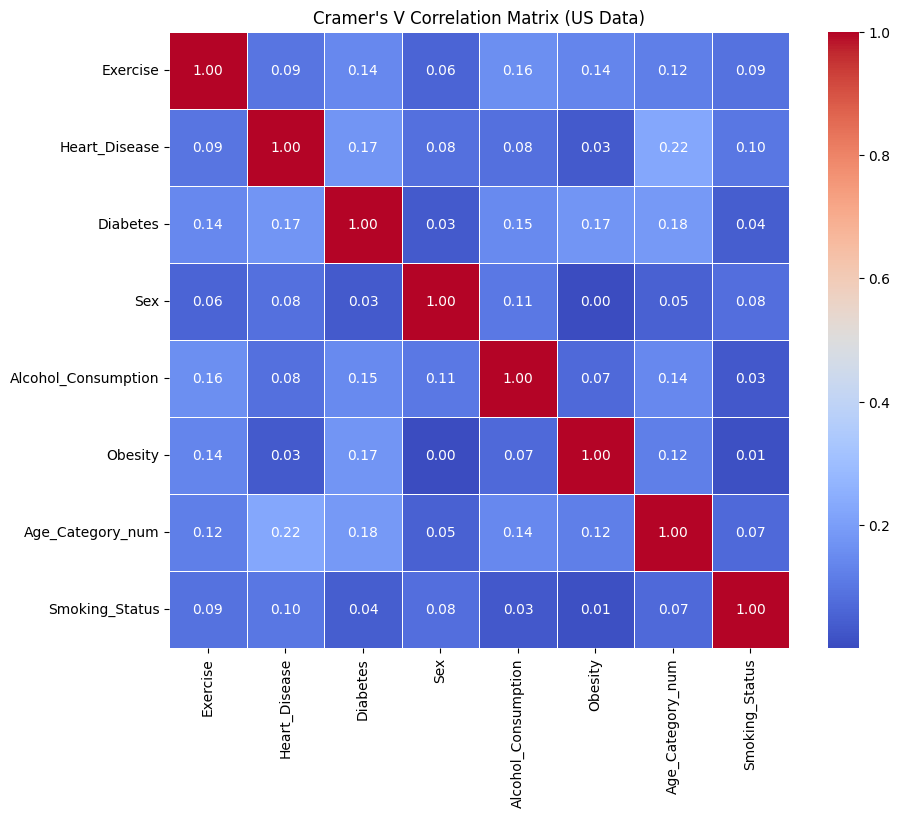

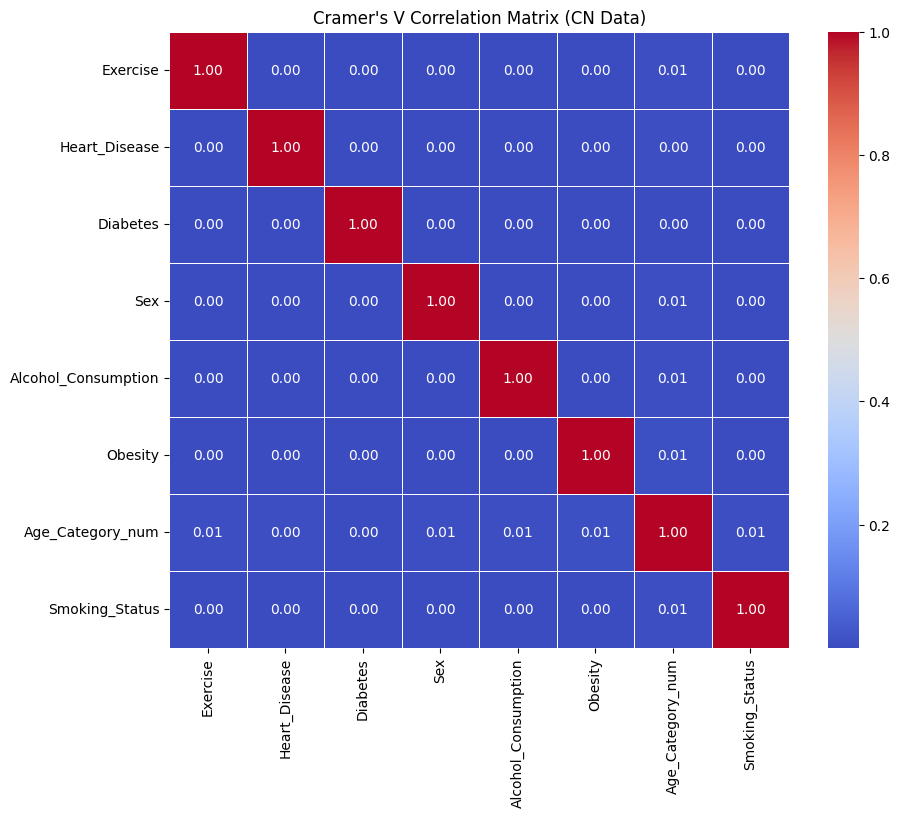

In [ ]:
import seaborn as sb
import matplotlib.pyplot as plt

# Plot heatmap for US data
plt.figure(figsize=(10, 8))
sb.heatmap(us_cramer_matrix.astype(float), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Cramer\'s V Correlation Matrix (US Data)')
plt.show()

# Plot heatmap for CN data
plt.figure(figsize=(10, 8))
sb.heatmap(cn_cramer_matrix.astype(float), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Cramer\'s V Correlation Matrix (CN Data)')
plt.show()

### Variance Inflation Factor

Actually, there is a more powerful tool to check our data. The Variance Inflation Factor can measure multicollinearity in one statistic, and this measures collinearity between one variable and all the others. A VIF above 5 is considered concerning.

In [ ]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

print("US Data VIF: \n")

for i, value in enumerate(us_data.columns):
	vif = variance_inflation_factor(us_data, i)
	print(i, value, vif)

print("\n")

print("US Data VIF: \n")

for i, value in enumerate(cn_data.columns):
	vif = variance_inflation_factor(cn_data, i)
	print(i, value, vif)

US Data VIF: 

0 Exercise 3.682435407528186
1 Heart_Disease 1.1952695998998137
2 Diabetes 1.2997935079921816
3 Sex 2.0655011425339835
4 Alcohol_Consumption 2.1349952804676597
5 Obesity 1.5072352044329325
6 Age_Category_num 6.118779083006777
7 Smoking_Status 1.7492430904814944


US Data VIF: 

0 Diabetes 1.117067406622306
1 Obesity 1.3933910185839304
2 Smoking_Status 1.8860627174693267
3 Alcohol_Consumption 1.3963772746355316
4 Exercise 2.655568019610953
5 Heart_Disease 1.1293207583741025
6 Age_Category_num 4.3616456404036565
7 Sex 1.8894377316929916


Both Cramer V and VIF appears small, so the assumption of no collinearity holds.

###Testing log-odds linearity

Another assumption is that the log-odds should be linear. That means that the probability of heart disease should increase linearly with the increase of some continuous variable. In our regression, we do have a continuous variable of age. Usually, you would expect that the probability of heart disease does not increase linearly with age — the increase in heart disease chances would likely be smaller between age 30 and 40 as compared to 70 to 80.

   age_bucket country  log_odds
0        70.0      us -1.761186
0        60.0      us -2.278594
0        75.0      us -1.508156
0        80.0      us -1.277117
0        65.0      us -2.047110
0        50.0      us -3.008186
0        45.0      us -3.398736
0        30.0      us -4.507354
0        55.0      us -2.571880
0        35.0      us -4.306823
0        40.0      us -3.884522
0        55.0      cn -1.999024
0        65.0      cn -1.983328
0        45.0      cn -1.980066
0        35.0      cn -1.952499
0        75.0      cn -1.958850
0        80.0      cn -1.980381
0        50.0      cn -1.999788
0        60.0      cn -1.988274
0        30.0      cn -1.974206
0        70.0      cn -1.984822
0        40.0      cn -1.959410


/tmp/ipython-input-1852637900.py:10: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  age_logodds = pandas.concat([age_logodds, pandas.DataFrame({"age_bucket": [age_bucket], "country": "us", "log_odds": [logodds]})])


<Axes: xlabel='age_bucket', ylabel='log_odds'>

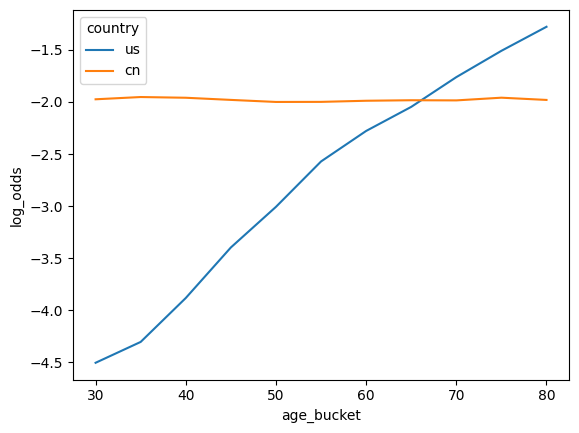

In [ ]:
age_counts_us = us_data[["Age_Category_num", "Heart_Disease"]].value_counts().reset_index(name="count")
age_counts_cn = cn_data[["Age_Category_num", "Heart_Disease"]].value_counts().reset_index(name="count")

age_logodds = pandas.DataFrame(columns=["age_bucket", "country", "log_odds"])
for age_bucket in us_data["Age_Category_num"].unique():
	positive_count = age_counts_us.query(f"Age_Category_num == {age_bucket} and Heart_Disease == 1.0").iloc[0]["count"]
	total_count = positive_count + age_counts_us.query(f"Age_Category_num == {age_bucket} and Heart_Disease == 0.0").iloc[0]["count"]
	p = positive_count / total_count
	logodds = math.log(p/(1-p))
	age_logodds = pandas.concat([age_logodds, pandas.DataFrame({"age_bucket": [age_bucket], "country": "us", "log_odds": [logodds]})])

for age_bucket in cn_data["Age_Category_num"].unique():
	positive_count = age_counts_cn.query(f"Age_Category_num == {age_bucket} and Heart_Disease == 1.0").iloc[0]["count"]
	total_count = positive_count + age_counts_cn.query(f"Age_Category_num == {age_bucket} and Heart_Disease == 0.0").iloc[0]["count"]
	p = positive_count / total_count
	logodds = math.log(p/(1-p))
	age_logodds = pandas.concat([age_logodds, pandas.DataFrame({"age_bucket": [age_bucket], "country": "cn", "log_odds": [logodds]})])

print(age_logodds)

sb.lineplot(age_logodds, hue="country", x="age_bucket", y="log_odds")

Surprisingly, the increase in log-odds appears pretty linear as the age buckets increase. While the odds increase with age in the US data as one would expect, in the Chinese data the odds appear to remain constant. <small>*This isn't going to be the last time my eyebrows cock upwards at the results from the Chinese data...*</small>

We can thus conclude from our exploratory analysis that there is no strong association between variables and target variable ```Heart_Disease```, and No strong multicolinearity **except for age**. Variables are independent of each other. Logistic regression is thus an optimal choice for modelling ```Heart_Disease```.

The age variable seems to have high colinearity, which makes sense in the real world as many health problems tend to worsen with age. In the Chinese data, the risk of heart disease also appears to be completely unaffected by age which is highly suspect. As such, we made the decision to drop the age variable.

## 4. Logistic regression

In [ ]:
'''from sklearn.preprocessing import SplineTransformer

spline = SplineTransformer(knots="quantile", n_knots=4, degree=3, extrapolation="linear") # defaults to cubic spline

us_age_spline = spline.fit_transform(us_data[['Age_Category_num']])
cn_age_spline = spline.fit_transform(cn_data[['Age_Category_num']])

# Create new column names for the spline features
us_spline_cols = [f'Age_spline_{i}' for i in range(us_age_spline.shape[1])]
cn_spline_cols = [f'Age_spline_{i}' for i in range(cn_age_spline.shape[1])]

# Convert the spline transformed arrays back to DataFrames
us_age_spline_df = pandas.DataFrame(us_age_spline, columns=us_spline_cols, index=us_data.index)
cn_age_spline_df = pandas.DataFrame(cn_age_spline, columns=cn_spline_cols, index=cn_data.index)

# Concatenate the original dataframes with the new spline features
us_data = pandas.concat([us_data, us_age_spline_df], axis=1)
cn_data = pandas.concat([cn_data, cn_age_spline_df], axis=1)

# Drop the original Age_Category_num column as it's now represented by the spline features
us_data.drop('Age_Category_num', axis=1, inplace=True)
cn_data.drop('Age_Category_num', axis=1, inplace=True)


print("US Data with Age Spline Features:")
display(us_data.head())
print("\nCN Data with Age Spline Features:")
display(cn_data.head())'''

'from sklearn.preprocessing import SplineTransformer\n\nspline = SplineTransformer(knots="quantile", n_knots=4, degree=3, extrapolation="linear") # defaults to cubic spline\n\nus_age_spline = spline.fit_transform(us_data[[\'Age_Category_num\']])\ncn_age_spline = spline.fit_transform(cn_data[[\'Age_Category_num\']])\n\n# Create new column names for the spline features\nus_spline_cols = [f\'Age_spline_{i}\' for i in range(us_age_spline.shape[1])]\ncn_spline_cols = [f\'Age_spline_{i}\' for i in range(cn_age_spline.shape[1])]\n\n# Convert the spline transformed arrays back to DataFrames\nus_age_spline_df = pandas.DataFrame(us_age_spline, columns=us_spline_cols, index=us_data.index)\ncn_age_spline_df = pandas.DataFrame(cn_age_spline, columns=cn_spline_cols, index=cn_data.index)\n\n# Concatenate the original dataframes with the new spline features\nus_data = pandas.concat([us_data, us_age_spline_df], axis=1)\ncn_data = pandas.concat([cn_data, cn_age_spline_df], axis=1)\n\n# Drop the original

In order to perform Logistic Regression, we first combine the two datasets (while labelling which country the data came from) and then check the interaction between the variables and the country. In this way, the coefficients fromthe logistic regression model measures the difference bwteen the influence of each factor between the countries.

In [ ]:
# Merge datasets to create interaction model
us_data["is_China"] = 0
cn_data["is_China"] = 1

merged = pandas.concat([us_data, cn_data], ignore_index=True)
merged

,Exercise,Heart_Disease,Diabetes,Sex,Alcohol_Consumption,Obesity,Age_Category_num,Smoking_Status,is_China
0,0.0,0.0,0.0,1.0,0.0,0.0,70.0,1.0,0
1,0.0,1.0,1.0,1.0,0.0,0.0,70.0,0.0,0
2,1.0,0.0,1.0,1.0,1.0,1.0,60.0,0.0,0
3,1.0,1.0,1.0,0.0,0.0,0.0,75.0,0.0,0
4,0.0,0.0,0.0,0.0,0.0,0.0,80.0,1.0,0
...,...,...,...,...,...,...,...,...,...
513940,1.0,1.0,0.0,0.0,0.0,0.0,50.0,0.0,1
513941,1.0,0.0,0.0,1.0,0.0,1.0,45.0,0.0,1
513942,1.0,0.0,0.0,0.0,0.0,0.0,55.0,1.0,1
513943,1.0,1.0,0.0,1.0,0.0,0.0,40.0,0.0,1


In [ ]:
from statsmodels.formula.api import logit
import math

itaction_log_reg = logit("Heart_Disease ~ (Exercise + Diabetes + Sex + Alcohol_Consumption + Obesity + Smoking_Status) * is_China", data=merged)

_fitted = itaction_log_reg.fit()
print(_fitted.summary())

Optimization terminated successfully.
         Current function value: 0.321752
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          Heart_Disease   No. Observations:               513945
Model:                          Logit   Df Residuals:                   513931
Method:                           MLE   Df Model:                           13
Date:                Wed, 12 Nov 2025   Pseudo R-squ.:                 0.04067
Time:                        13:20:49   Log-Likelihood:            -1.6536e+05
converged:                       True   LL-Null:                   -1.7237e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -1.9972      0.019   -103.884      0.000

```statsmodels``` provides a nice summary of the logistic regression results. We see that the *p*-values are all zero, whioch indicates these are all statistically significant results. I have been reassured that the pseudo R<sup>2</sup> value of 0.08 is acceptable in real world data. (usually, this means the model doesn't fit the data well.)

Because we combined both datasets and created an interaction model, the ```:is_China``` variables are the coefficients of the interaction, i.e. the change in "probability" when the same variables are in China.

The coefficients are a bit more difficult to directly interpret, so below is a table of the Odds Ratio instead.

In [ ]:
odds_ratio = pandas.DataFrame(columns=["variable", "us_odds_ratio_lower", "cn_odds_ratio_lower", "diff_lower", "us_odds_ratio_upper", "cn_odds_ratio_upper", "diff_upper"])

for variable in _fitted.params.index:
	if variable in ["Exercise", "Diabetes", "Sex", "Alcohol_Consumption", "Obesity", "Smoking_Status", "Age_Category_num"]:
		odds_ratio = pandas.concat([odds_ratio, pandas.DataFrame({"variable": variable, "us_odds_ratio_lower": [_fitted.conf_int().loc[variable, 0]], "cn_odds_ratio_lower": [_fitted.conf_int().loc[variable, 0] + _fitted.conf_int().loc[f"{variable}:is_China", 0]], "diff_lower": [_fitted.conf_int().loc[f"{variable}:is_China", 0]], "us_odds_ratio_upper": [_fitted.conf_int().loc[variable, 1]], "cn_odds_ratio_upper": [_fitted.conf_int().loc[variable, 1] + _fitted.conf_int().loc[f"{variable}:is_China", 1]], "diff_upper": [_fitted.conf_int().loc[f"{variable}:is_China", 1]]})])

odds_ratio = pandas.concat([odds_ratio, pandas.DataFrame({"variable": "(all other variables 0)", "us_odds_ratio_lower": [_fitted.conf_int().loc["Intercept", 0]], "cn_odds_ratio_lower": [_fitted.conf_int().loc["Intercept", 0] + _fitted.conf_int().loc["is_China", 0]], "diff_lower": [_fitted.conf_int().loc["is_China", 0]], "us_odds_ratio_upper": [_fitted.conf_int().loc["Intercept", 1]], "cn_odds_ratio_upper": [_fitted.conf_int().loc["Intercept", 1] + _fitted.conf_int().loc["is_China", 1]], "diff_upper": [_fitted.conf_int().loc["is_China", 1]]})])

odds_ratio = odds_ratio.set_index("variable")
odds_ratio = odds_ratio.map(lambda x: math.exp(x))

odds_ratio

/tmp/ipython-input-1814138005.py:5: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  odds_ratio = pandas.concat([odds_ratio, pandas.DataFrame({"variable": variable, "us_odds_ratio_lower": [_fitted.conf_int().loc[variable, 0]], "cn_odds_ratio_lower": [_fitted.conf_int().loc[variable, 0] + _fitted.conf_int().loc[f"{variable}:is_China", 0]], "diff_lower": [_fitted.conf_int().loc[f"{variable}:is_China", 0]], "us_odds_ratio_upper": [_fitted.conf_int().loc[variable, 1]], "cn_odds_ratio_upper": [_fitted.conf_int().loc[variable, 1] + _fitted.conf_int().loc[f"{variable}:is_China", 1]], "diff_upper": [_fitted.conf_int().loc[f"{variable}:is_China", 1]]})])


,us_odds_ratio_lower,cn_odds_ratio_lower,diff_lower,us_odds_ratio_upper,cn_odds_ratio_upper,diff_upper
variable,,,,,,
Exercise,0.612938,0.926089,1.510901,0.649924,1.061938,1.633942
Diabetes,2.836855,0.923124,0.325404,3.015699,1.083719,0.359359
Sex,0.530677,0.944790,1.780349,0.560896,1.075275,1.917067
Alcohol_Consumption,0.598225,0.938573,1.568930,0.632685,1.072525,1.695196
Obesity,0.955448,0.950222,0.994530,1.011161,1.087070,1.075071
Smoking_Status,1.774572,0.929940,0.524036,1.874186,1.056958,0.563955
(all other variables 0),0.130693,0.126925,0.971173,0.140923,0.150699,1.069375


The Odds Ratio tells you how much more heart disease is likely to happen as compared to not happen in the prescence of that variable *only*. It is presented here as a range; this is the 97.5% confidence interval. That means the predicted odds ratio is 97.5% likely to be correct. For our research question, we wanted to compare which variable has a larger influence between the countries, so we can compare the difference in odds ratios for each variables.


**Conclusion**

According to our logistic regression, for the Americans, diabetes is the greatest factor influencing whether someone has heart disease, followed by smoking. The Chinese data we have however all have odds ratios around 1, indicating none of the factors considered have a strong influence. Comparing between both countries, sex (specifically, being a woman) seems to be a lot stronger of an influence in China than in the US, although the actual odds aren't that pronounced.



## 5. Random Forest Classifier

Random Forest combines multiple decision trees to improve prediction accuracy and stability. It works well with both numerical and categorical data, making it suitable for our dataset. By training separate models for China and the USA, we can identify which factors are most important in predicting cardiovascular disease within each population using the feature importance scores.



=== Feature Importance Comparison (China vs USA) ===
              Variable  Importance_China  Importance_USA
1                  Sex          0.175088        0.153330
2             Diabetes          0.173528        0.412850
3              Obesity          0.170357        0.007402
4  Alcohol_Consumption          0.161726        0.121955
5       Smoking_Status          0.160104        0.186807
6             Exercise          0.159196        0.117657


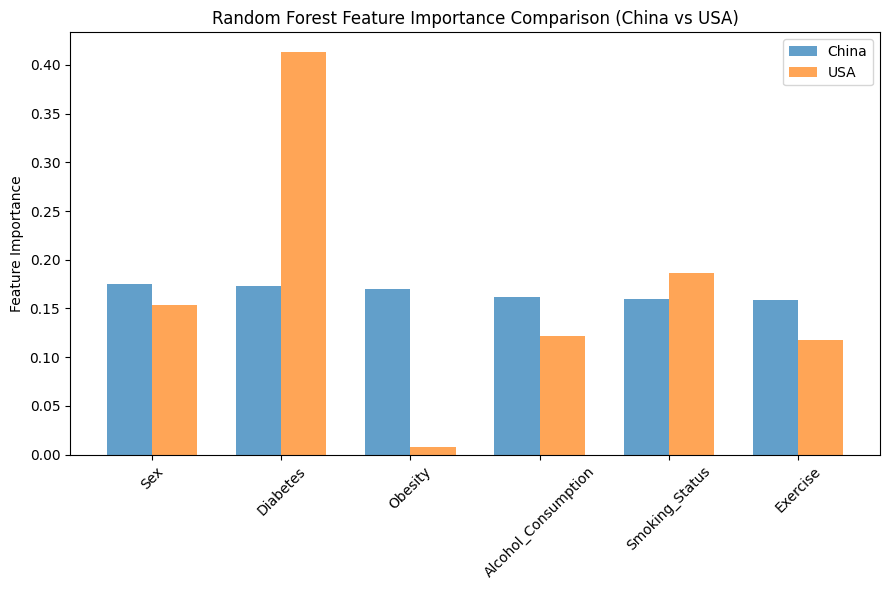

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt


def encode_yes_no(df):
    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].map({'Yes': 1, 'No': 0, 'Male': 1, 'Female': 0}).fillna(df[col])
    return df

cn_data = encode_yes_no(cn_data)
us_data = encode_yes_no(us_data)


def get_feature_importance(df):
    target_col = "Heart_Disease"
    X = df.drop(columns=[target_col, "is_China", "Age_Category_num"])
    y = df[target_col]

    model = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
    model.fit(X, y)

    importance = pd.DataFrame({
        'Variable': X.columns,
        'Importance': model.feature_importances_
    }).sort_values('Importance', ascending=False).reset_index(drop=True)
    return importance


china_importance = get_feature_importance(cn_data)
usa_importance = get_feature_importance(us_data)

merged_importance = pd.merge(
    china_importance,
    usa_importance,
    on='Variable',
    suffixes=('_China', '_USA')
).sort_values(by='Importance_China', ascending=False).reset_index(drop=True)
merged_importance.index += 1

print("\n=== Feature Importance Comparison (China vs USA) ===")
print(merged_importance)


plt.figure(figsize=(9,6))
bar_width = 0.35
variables = merged_importance['Variable']
x = range(len(variables))

plt.bar(x, merged_importance['Importance_China'], width=bar_width, alpha=0.7, label='China')
plt.bar([i + bar_width for i in x], merged_importance['Importance_USA'], width=bar_width, alpha=0.7, label='USA')

plt.xticks([i + bar_width/2 for i in x], variables, rotation=45)
plt.ylabel('Feature Importance')
plt.title('Random Forest Feature Importance Comparison (China vs USA)')
plt.legend()
plt.tight_layout()
plt.show()

**Conclusion:**

Since the factor with the highest feature importance score is **Age**, it  is the strongest influence of the risk of a person getting heart disease for both countries.